In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import genpareto
from sklearn.linear_model import LinearRegression, QuantileRegressor
from sklearn.metrics import mean_absolute_error, r2_score, mean_pinball_loss

# Week 7: Niche Regression Tools

## Last Week

1. Introduced train-val-test split
2. Discussed linreg, regularization, random forests, and gradient boosting.

#### The above regression methods are greatly useful, but they don't give the most consideration to extreme values.

## Fake Dataset

I had ChatGPT generate a fake sales dataset, where `daily_orders` is the response variable, and `ad_spend_usd`, `website_visits`, `discount_pct`, and `email_campaign` are the predictors.

### Loading In

In [ ]:
df = pd.read_csv("synthetic_online_store_orders.csv")
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date")


In [36]:
df.head()

,date,ad_spend_usd,website_visits,discount_pct,email_campaign,daily_orders
0,2023-01-01,318,1174,0,1,111
1,2023-01-02,202,778,0,0,52
2,2023-01-03,261,1001,10,0,189
3,2023-01-04,193,1066,25,0,109
4,2023-01-05,229,1119,20,0,102


### Train-Test Split

In [23]:
features = [
    "ad_spend_usd",
    "website_visits",
    "discount_pct",
    "email_campaign"
]

split = int(len(df) * 0.8)

train = df.iloc[:split]
test = df.iloc[split:]

X_train, X_test = train[features], test[features]
y_train, y_test = train["daily_orders"], test["daily_orders"]


## Quantile Regression

**What is it?**
<br> Ordinary regression predicts the mean (expected) value of a response variable. Quantile regression predicts different percentiles (i.e. the cutoff of response variables). It measures how certain ends of a distribution change with predictors. It's best used for tails, since OLS already handles more modest values well. 
<br>

**Why us it?**
1. Sometimes a dataset contains several values that aren't well explained or captured by a mean estimate.
2. QuantReg allows us to compare the importance of variables across percentiles.

**EX:** 
Let's say a 95th-percentile QuantReg model predicts 60-minute delay threshold for high temperatures and a 140-minute delay threshold for strong winds. That implies that strong winds are more closely tied to the upper tail of delays than high temperatures.

### Fitting Models: OLS vs. Quantile Regression

In [ ]:
# Fit three models
ols = LinearRegression().fit(X_train, y_train)
q50 = QuantileRegressor(quantile=0.50, alpha=0).fit(X_train, y_train)
q90 = QuantileRegressor(quantile=0.90, alpha=0).fit(X_train, y_train)
# QuantileRegressor() regularizes by default. alpha=0 turns that off

pred_ols = ols.predict(X_test)
pred_q50 = q50.predict(X_test)
pred_q90 = q90.predict(X_test)

print("OLS MAE:", mean_absolute_error(y_test, pred_ols))
print("OLS r2:", r2_score(y_test, pred_ols))
print("Median Quantile MAE:", mean_absolute_error(y_test, pred_q50))

print("Q50 Pinball Loss:",
      mean_pinball_loss(y_test, pred_q50, alpha=0.50))
print("Q90 Pinball Loss:",
      mean_pinball_loss(y_test, pred_q90, alpha=0.90))
# pinball loss --> how well a model estimates its specified quantile
# for higher percentiles, you don't want too high of predictions
# for lower percentiles, you don't want too low of predictions
# this prevents consistent overestimation or underestimation just to capture extreme values
# calculation of PL is asymmetric across models and should not be compared

print("Q50 Coverage:", np.mean(y_test <= pred_q50))
print("Q90 Coverage:", np.mean(y_test <= pred_q90))
# coverage --> the percentage of observations falling at or below the estimated quantile

OLS MAE: 21.74459940191292
OLS r2: 0.3067462578116096
Median Quantile MAE: 21.180045033549625
Q50 Pinball Loss: 10.590022516774813
Q90 Pinball Loss: 5.051935552370335
Q50 Coverage: 0.5529411764705883
Q90 Coverage: 0.9470588235294117


**Notice anything?**

### Visualization

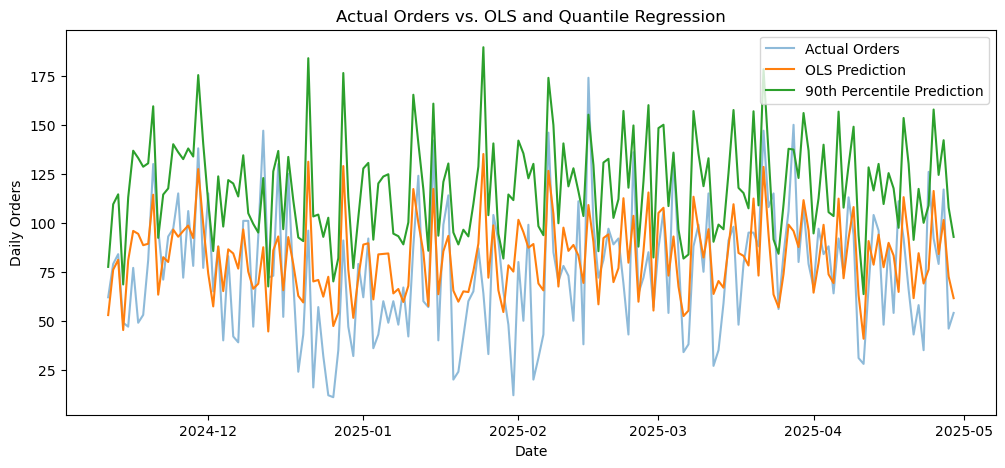

In [ ]:
# how accurate are our model's cutoffs?
plt.figure(figsize=(12, 5))

plt.plot(test["date"], y_test, label="Actual Orders", alpha=0.5)
plt.plot(test["date"], pred_ols, label="OLS Prediction")
plt.plot(test["date"], pred_q90, label="90th Percentile Prediction")

plt.xlabel("Date")
plt.ylabel("Daily Orders")
plt.title("Actual Orders vs. OLS and Quantile Regression")
plt.legend()
plt.show()

### Comparing Coefficients

In [29]:
coefficients = pd.DataFrame({
    "Feature": features,
    "OLS": ols.coef_,
    "Q50": q50.coef_,
    "Q90": q90.coef_
})

print(coefficients)

          Feature       OLS       Q50       Q90
0    ad_spend_usd  0.017627  0.035295  0.048256
1  website_visits  0.066945  0.068106  0.087647
2    discount_pct  0.675211  0.629601  0.716239
3  email_campaign  4.585217  2.811922  4.581781


## Generalized Pareto Distributions (Ignore, Scroll Past)

**What is it?**

### Fitting

In [30]:
threshold = y_train.quantile(0.95)

train_excess = y_train[y_train > threshold] - threshold
test_excess = y_test[y_test > threshold] - threshold

shape, loc, scale = genpareto.fit(train_excess, floc=0)

print("Threshold:", threshold)
print("Training exceedances:", len(train_excess))
print("Testing exceedances:", len(test_excess))
print("Shape:", shape)
print("Scale:", scale)

Threshold: 148.04999999999995
Training exceedances: 34
Testing exceedances: 2
Shape: 0.30987231632149137
Scale: 34.22081184774187


In [31]:
targets = [
    threshold + 20,
    threshold + 50,
    threshold + 100
]

train_exceedance_rate = (y_train > threshold).mean()

for target in targets:
    observed = (y_test > target).mean()

    predicted = train_exceedance_rate * genpareto.sf(
        target - threshold,
        shape,
        loc=0,
        scale=scale
    )

    print(f"Orders > {target:.0f}")
    print(f"  Observed probability:  {observed:.4f}")
    print(f"  Predicted probability: {predicted:.4f}")

Orders > 168
  Observed probability:  0.0059
  Predicted probability: 0.0292
Orders > 198
  Observed probability:  0.0000
  Predicted probability: 0.0150
Orders > 248
  Observed probability:  0.0000
  Predicted probability: 0.0062


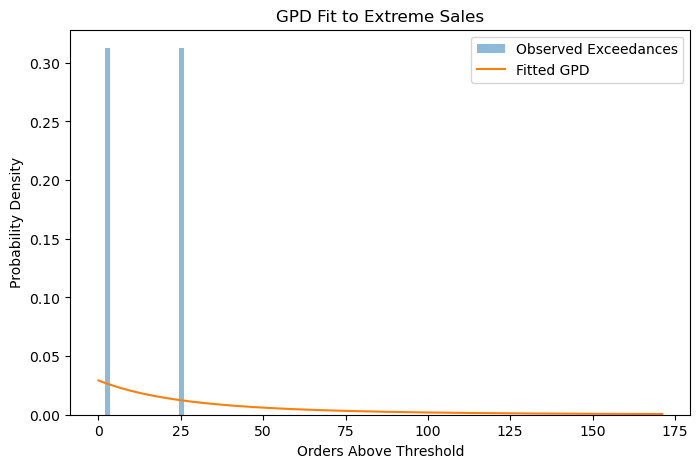

In [32]:
if len(test_excess) > 0:
    x = np.linspace(0, max(test_excess.max(), scale * 5), 200)

    plt.figure(figsize=(8, 5))

    plt.hist(
        test_excess,
        bins=15,
        density=True,
        alpha=0.5,
        label="Observed Exceedances"
    )

    plt.plot(
        x,
        genpareto.pdf(x, shape, loc=0, scale=scale),
        label="Fitted GPD"
    )

    plt.xlabel("Orders Above Threshold")
    plt.ylabel("Probability Density")
    plt.title("GPD Fit to Extreme Sales")
    plt.legend()
    plt.show()

## For next week
1. Make sure OLS, regularization, random forests, and gradient boosting is done (with the flight/weather data)
2. Experiment with quantile regression, especially looking at how different predictors vary in importance across percentiles (with the flight/weather data)

## Symposium Updates
1. Tuesday, Week 9, 6-7pm (probably Panda Express)
2. No paper, just presentation
3. Presentation will focus on learning/comparison rather than model accuracy
4. Each person will present on 1-2 topics they feel most comfortable explaining
5. We will start working on the presentation after next week's meeting

##